# Explanatory Data Analysis

<Axes: >

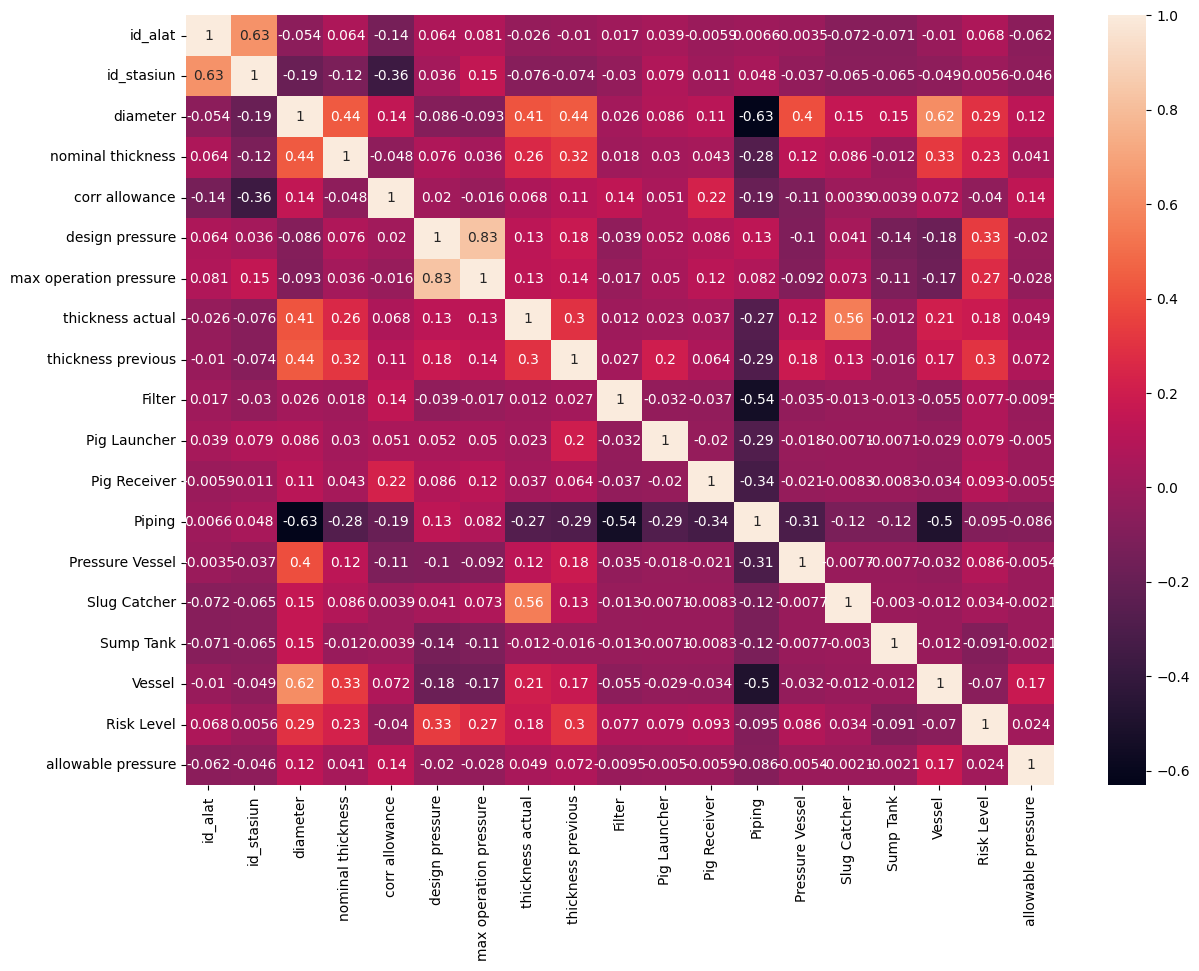

In [ ]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

df = pd.read_csv('Pipe risk.csv')
df = df.drop('Stasiun', axis=1)
le = LabelEncoder()
df['Risk Level'] = le.fit_transform(df['Risk Level'])

# Scatter plot
# sns.jointplot(data=df, x='diameter', y='max operation pressure',hue='Risk Level') # joint plot

# Correlation heat map
plt.figure(figsize=(14,10))
sns.heatmap(df.corr(), annot=True)

# Preprocessing

In [ ]:
df.head()
X = df.iloc[:,:-2].values
Y = df.iloc[:,-2].values

# Feature selection
k = 5 # top k best feature
from sklearn.feature_selection import SelectKBest

best_features = SelectKBest(k=k)
X = best_features.fit_transform(X,Y)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,Y,test_size=0.3)

# Making the Model

In [ ]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier()
params = {'n_estimators': [2,10,50,100,1000]}
          # 'criterion': []} contoh

# Hyperparameter optimization with Grid Search
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(estimator=model, param_grid=params, cv=5)
grid.fit(X_train,y_train)
print(grid.best_params_)

model = grid.best_estimator_ # RandomForestClassifier(n_estimators = 100)
model.fit(X_train, y_train)

y_pred = model.predict(X_test) # result in predicted y

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test,y_pred)
print('Random Forest Result Accuracy:',accuracy*100)

from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(model, X, Y, cv=10, scoring='accuracy')
print('Average Accuracy',cv_scores.mean()*100)
print('Std accuracy', cv_scores.std()*1.96*100)

{'n_estimators': 10}
Random Forest Result Accuracy: 97.01492537313433
Average Accuracy 95.07236544549977
Std accuracy 13.784391412455122


# Visualisasi

['Low Risk' 'Medium High Risk' 'Medium Risk']


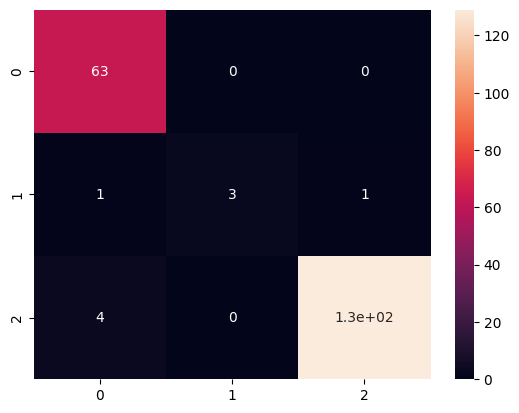

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test,y_pred) # Confusion matrix as number
sns.heatmap(cm,annot=True) # confusion matrix image

print(le.classes_)